# Step 11 — 2D Helmholtz Equation

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jejjohnson/sesmax/blob/main/docs/notebooks/step11_helmholtz_2d.ipynb)

*Part of [Steps to Navier–Stokes](../guide/steps_to_navier_stokes.md), after Lorena Barba's CFD Python; moved from somax's tutorial series.*

The [Helmholtz equation](https://en.wikipedia.org/wiki/Helmholtz_equation) generalises the Poisson equation with a screening term:

$$
(\nabla^2 - \lambda) \phi = f
$$

When $\lambda = 0$ this reduces to the Poisson equation from Step 10 (written there with $p$ and $b$ in place of $\phi$ and $f$). When $\lambda > 0$ the extra term *screens* the solution, suppressing long-range influences and reducing the amplitude.

**Physics:**

- **Quasi-geostrophic PV inversion:** $(\nabla^2 - F) \psi = q$, where $\psi$ is the streamfunction, $q$ the potential vorticity and $F$ the inverse Rossby deformation radius squared. Larger $F$ (smaller deformation radius) screens the flow, making eddies more localised. This is the case $\lambda = F$, $\phi = \psi$, $f = q$.
- **Yukawa screening:** In plasma physics and particle physics, the screened Poisson equation models exponentially-decaying potentials.
- **Reaction-diffusion steady states:** Diffusion with linear decay leads to a Helmholtz-type equation.

**What you will learn:**

1. How to create and use the `HelmholtzSolver2D`
2. How increasing $\lambda$ screens the solution
3. That $\lambda = 0$ recovers the Poisson solution exactly

### Symbols

The page uses the classic CFD letters. Everything is nondimensional, and $x$, $y$ are the spatial coordinates (there is no inference state on this page).

| Symbol | Meaning | Shape |
| --- | --- | --- |
| $x \in [0, L_x]$, $y \in [0, L_y]$ | spatial coordinates | $\mathbb{R}$ |
| $L_x$, $L_y$ | domain lengths, both $1$ here | $\mathbb{R}_{>0}$ |
| $N_{\Omega_x,x}$, $N_{\Omega_x,y}$ | number of interior cells in $x$ and in $y$ | count |
| $\phi(x, y)$ | the solved field | $\mathbb{R}$ |
| $f(x, y)$ | the source, the right-hand side | $\mathbb{R}$ |
| $\lambda$ | screening parameter, $\lambda \ge 0$ | $\mathbb{R}_{\ge 0}$ |
| $\kappa_{mn}$ | eigenvalue of $\nabla^2$ for the spectral mode $(m, n)$ | $\mathbb{R}$ |
| $\phi_{j,i}$, $f_{j,i}$ | the fields in the cell of row $j$ and column $i$; the arrays with ghosts have $N_{\Omega_x,y} + 2$ rows and $N_{\Omega_x,x} + 2$ columns | $\mathbb{R}$ |
| $\psi$, $q$, $F$ | streamfunction, potential vorticity and deformation parameter of the QG example only | $\mathbb{R}$ |

## Grid layout and boundary conditions

The solver works on the arrays of the [C-grid page](cgrid_and_boundaries.ipynb). The spectral solver operates on **interior cells** only. The boundary condition type determines which spectral transform is used.

**Dirichlet BCs** ($\phi = 0$ on the boundary): The DST (Discrete Sine Transform) automatically enforces zero values at the domain edges. Ghost cells are set to the negative of the nearest interior cell: `ghost = -interior` (antisymmetric). The screening parameter $\lambda$ does not change the boundary treatment: it only modifies the spectral-space eigenvalues from $\kappa_{mn}$ to $\kappa_{mn} - \lambda$.

## Setup

On Colab, install `sesmax-core`; locally, with the repository's environment, this does nothing.

In [1]:
import subprocess
import sys


try:
    import google.colab  # noqa: F401

    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    subprocess.run(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "-q",
            "sesmax-core @ git+https://github.com/jejjohnson/sesmax@main"
            "#subdirectory=packages/sesmax-core",
        ],
        check=True,
    )

In [2]:
import jax.numpy as jnp
import matplotlib.pyplot as plt

import sesmax_core.testing as sxt

In [3]:
import importlib.util


try:
    from IPython import get_ipython

    ipython = get_ipython()
except ImportError:
    ipython = None

if ipython is not None and importlib.util.find_spec("watermark") is not None:
    ipython.run_line_magic("load_ext", "watermark")
    ipython.run_line_magic("watermark", "-v -m -p jax,equinox,diffrax,sesmax_core")
else:
    print("watermark extension not installed; skipping reproducibility readout.")

Python implementation: CPython
Python version       : 3.13.12
IPython version      : 9.10.0

jax        : 0.12.0.1
equinox    : 0.13.8
diffrax    : 0.7.2
sesmax_core: 0.0.0

Compiler    : Clang 21.1.4 
OS          : Linux
Release     : 6.8.0-1044-azure
Machine     : x86_64
Processor   : x86_64
CPU cores   : 16
Architecture: 64bit



## 1. Setup

We use a sinusoidal source term on $[0, 1]^2$ with homogeneous Dirichlet BCs and solve the Helmholtz equation at several values of $\lambda$:

$$
f(x, y) = \sin(\pi x) \sin(\pi y)
$$

In [4]:
# Shapes: N_Ωx,y + 2 rows and N_Ωx,x + 2 columns with the ghosts;
# N_Ωx,y, N_Ωx,x interior; G = (N_Ωx,y + 2) × (N_Ωx,x + 2) with the ghosts

num_x = 64
num_y = 64
length_x = 1.0
length_y = 1.0

# today (sesmax_core)
# reference Poisson solver, the λ = 0 case
poisson = sxt.PoissonSolver2D.create(
    nx=num_x, ny=num_y, Lx=length_x, Ly=length_y, bc="dirichlet"
)

# xᵢ = i Δx
x_index = jnp.arange(poisson.grid.Nx)  # → (N_Ωx,x + 2,)
x_position = x_index * poisson.grid.dx  # → (N_Ωx,x + 2,)
# yⱼ = j Δy
y_index = jnp.arange(poisson.grid.Ny)  # → (N_Ωx,y + 2,)
y_position = y_index * poisson.grid.dy  # → (N_Ωx,y + 2,)
x_mesh, y_mesh = jnp.meshgrid(x_position, y_position)  # → G

# f = sin(π x) sin(π y)
sine_x = jnp.sin(jnp.pi * x_mesh)  # → G
sine_y = jnp.sin(jnp.pi * y_mesh)  # → G
source = sine_x * sine_y  # → G

## 2. Screening effect

We solve $(\nabla^2 - \lambda) \phi = f$ for $\lambda \in \{0, 1, 10, 100\}$. As $\lambda$ increases the solution amplitude should decrease and the field should become more localised.

In [5]:
# Shapes: N_Ωx,y + 2 rows and N_Ωx,x + 2 columns with the ghosts;
# N_Ωx,y, N_Ωx,x interior; G = (N_Ωx,y + 2) × (N_Ωx,x + 2) with the ghosts

interior_cells = slice(1, -1)
interior = (interior_cells, interior_cells)

screening_values = [0.0, 1.0, 10.0, 100.0]
solutions = {}

for screening in screening_values:
    # today (sesmax_core)
    solver = sxt.HelmholtzSolver2D.create(
        nx=num_x, ny=num_y, Lx=length_x, Ly=length_y, lambda_=screening, bc="dirichlet"
    )
    # (∇² − λ) φ = f
    # today (sesmax_core)
    solution = solver.solve(source)  # → G
    solutions[screening] = solution
    # max |φ|
    amplitude = float(jnp.max(jnp.abs(solution[interior])))
    print(f"lambda = {screening:6.1f}  max|phi| = {amplitude:.6f}")

lambda =    0.0  max|phi| = 0.050671
lambda =    1.0  max|phi| = 0.048227
lambda =   10.0  max|phi| = 0.033630
lambda =  100.0  max|phi| = 0.008352


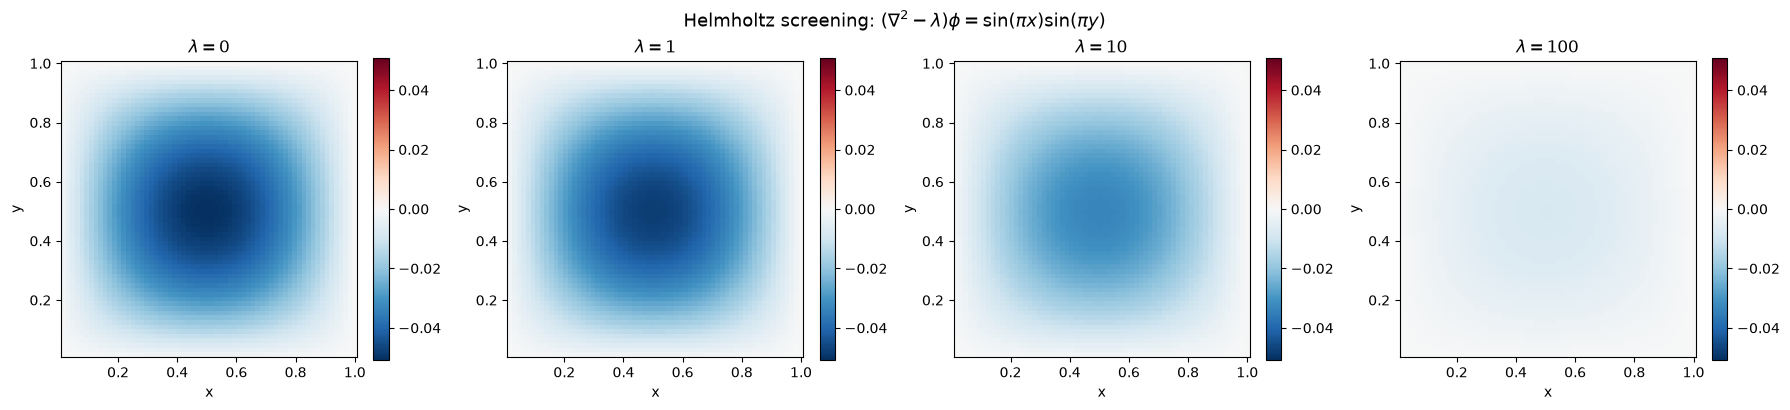

In [6]:
fig, axes = plt.subplots(1, 4, figsize=(18, 4))

# shared colour range from the λ = 0 solution
colour_limit = float(jnp.max(jnp.abs(solutions[0.0][interior])))

for ax, screening in zip(axes, screening_values, strict=False):
    solution = solutions[screening]
    im = ax.pcolormesh(
        x_mesh[interior],
        y_mesh[interior],
        solution[interior],
        shading="auto",
        vmin=-colour_limit,
        vmax=colour_limit,
        cmap="RdBu_r",
    )
    ax.set_title(rf"$\lambda = {screening:.0f}$")
    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_aspect("equal")
    plt.colorbar(im, ax=ax, fraction=0.046)

plt.suptitle(
    r"Helmholtz screening: $(\nabla^2 - \lambda)\phi = \sin(\pi x)\sin(\pi y)$",
    fontsize=13,
)
plt.tight_layout()
plt.show()

The amplitude drops dramatically with increasing $\lambda$. Physically, the screening term $-\lambda \phi$ acts as a restoring force that penalises large values of $\phi$, pulling the solution toward zero.

## 3. Cross-section comparison

A 1D slice along $y = 0.5$ (the centre row) shows the screening effect more clearly.

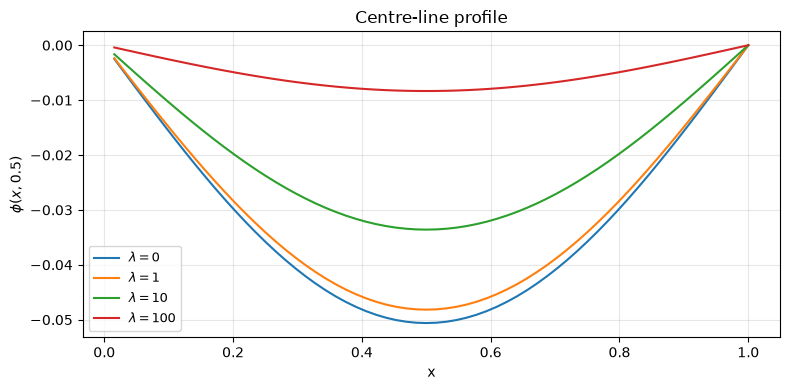

In [7]:
# Shapes: N_Ωx,y + 2 rows and N_Ωx,x + 2 columns with the ghosts

centre_row = poisson.grid.Ny // 2

fig, ax = plt.subplots(figsize=(8, 4))
for screening in screening_values:
    solution = solutions[screening]
    # φ(x, 0.5)
    profile = solution[centre_row, interior_cells]  # → (N_Ωx,x,)
    ax.plot(
        x_position[interior_cells],
        profile,
        label=rf"$\lambda = {screening:.0f}$",
        lw=1.5,
    )
ax.set_xlabel("x")
ax.set_ylabel(r"$\phi(x, 0.5)$")
ax.set_title("Centre-line profile")
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

## 4. Helmholtz at $\lambda = 0$ matches Poisson

When $\lambda = 0$ the Helmholtz equation reduces to the Poisson equation. We verify that the two solvers produce identical results.

In [8]:
# Shapes: N_Ωx,y + 2 rows and N_Ωx,x + 2 columns with the ghosts;
# G = (N_Ωx,y + 2) × (N_Ωx,x + 2) with the ghosts

# today (sesmax_core)
# ∇² φ = f
poisson_solution = poisson.solve(source)  # → G
helmholtz_solution = solutions[0.0]  # → G

# maxⱼᵢ |φⱼᵢ^Poisson − φⱼᵢ^Helmholtz|
difference = poisson_solution - helmholtz_solution  # → G
max_difference = jnp.max(jnp.abs(difference))  # → ()
print(f"Max |Poisson - Helmholtz(lambda=0)|: {float(max_difference):.2e}")

Max |Poisson - Helmholtz(lambda=0)|: 0.00e+00


The difference is at machine precision, confirming that the Helmholtz solver generalises the Poisson solver correctly.

> **Connection to finitevolX:** For more advanced use cases (e.g. multilayer QG models), `sesmax` also provides `DirichletHelmholtzCache` which wraps the `DirichletHelmholtzSolver2D` from `spectraldiffx` with a pre-configured Helmholtz parameter. See `sesmax_core._src.gfd.helmholtz` for details.

## 5. Amplitude vs. $\lambda$

For the single-mode source $f = \sin(\pi x) \sin(\pi y)$, the analytical solution of the Helmholtz equation is:

$$
\phi = \frac{f}{-2 \pi^2 - \lambda}
$$

So the peak amplitude scales as $1 / (2 \pi^2 + \lambda)$. Let us verify this over a wider range of $\lambda$.

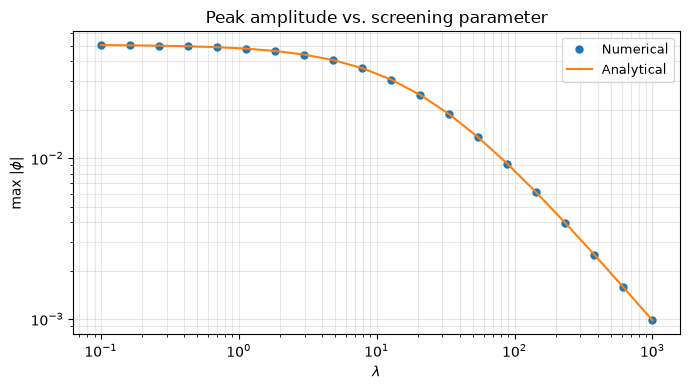

In [9]:
# Shapes: N_λ = 20 screening values;
# N_Ωx,y + 2 rows and N_Ωx,x + 2 columns with the ghosts;
# G = (N_Ωx,y + 2) × (N_Ωx,x + 2) with the ghosts

screening_range = jnp.logspace(-1, 3, 20)  # → (N_λ,)
numerical_amplitudes = []
analytical_amplitudes = []

for screening in screening_range:
    # today (sesmax_core)
    solver = sxt.HelmholtzSolver2D.create(
        nx=num_x,
        ny=num_y,
        Lx=length_x,
        Ly=length_y,
        lambda_=float(screening),
        bc="dirichlet",
    )
    # (∇² − λ) φ = f
    # today (sesmax_core)
    solution = solver.solve(source)  # → G
    # max |φ|
    numerical_amplitudes.append(float(jnp.max(jnp.abs(solution[interior]))))
    # 1 / (2π² + λ), the peak of f is 1
    denominator = 2.0 * jnp.pi**2 + float(screening)  # → ()
    analytical_amplitudes.append(1.0 / denominator)

fig, ax = plt.subplots(figsize=(7, 4))
ax.loglog(screening_range, numerical_amplitudes, "o", label="Numerical", markersize=5)
ax.loglog(screening_range, analytical_amplitudes, "-", label="Analytical", lw=1.5)
ax.set_xlabel(r"$\lambda$")
ax.set_ylabel(r"max $|\phi|$")
ax.set_title(r"Peak amplitude vs. screening parameter")
ax.legend(fontsize=9)
ax.grid(True, alpha=0.3, which="both")
plt.tight_layout()
plt.show()

## Summary

| Concept | API |
| --- | --- |
| Create Helmholtz solver | `HelmholtzSolver2D.create(nx, ny, lambda_=..., bc=...)` |
| Solve | `solver.solve(rhs)` |
| Poisson limit | `lambda_=0.0` recovers Poisson exactly |
| Screening | Larger $\lambda$ reduces amplitude and range |
| QG connection | $(\nabla^2 - F) \psi = q$ for PV inversion |

**Next:** [Step 12](step12_cavity_flow.ipynb) tackles the full Navier–Stokes equations with the lid-driven cavity benchmark.